# 12 — Tüm Algoritmaların Karşılaştırılması

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Bu bölüm, önceki on bir notebook'un ürettiği sonuç dosyalarını okur ve tek bir
tabloda birleştirir. Karşılaştırmanın adil olmasının koşulu, bütün modellerin aynı
veri, aynı bölünme ve aynı özelliklerle eğitilmiş olmasıdır; `ortak.py` bu koşulu
güvence altına alır.

Regresyon görevinde (yangın duyarlılık skoru) MAE, MSE (Brier skoru), RMSE, R² (Brier
beceri skoru) ve ROC-AUC; sınıflandırma görevinde doğruluk, dengeli doğruluk, F1-makro
ve F1-ağırlıklı raporlanır. Lojistik Regresyon ile Naive Bayes yalnızca sınıflandırma,
Lineer Regresyon yalnızca regresyon yapar.

**Taban çizgileri hatırlatması:** ortalama ve çoğunluk tabanları hiçbir şey bilmeyen
modeldir; tek kural tabanı (eğitim kümesinden öğrenilmiş tek bir eşik sorusu) ise
geçilmesi gereken asıl çizgidir. Aşağıdaki bütün sayılar bu çizgiler göz önünde
tutularak okunmalıdır.

## 1. Sonuçların Toplanması

In [1]:
import ortak as o
import os
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

df = o.veri_yukle()
tb = o.taban_cizgileri(df)
test = df[~o.egitim_maskesi(df)].reset_index(drop=True)

kayitlar = {}
for yol in sorted(glob.glob(os.path.join(o.SONUC_DIR, "*.json"))):
    ad = os.path.basename(yol)
    if ad.startswith("_"):          # yardımcı dosyalar bir algoritma sonucu değildir
        continue
    with open(yol, encoding="utf-8") as f:
        k = json.load(f)
    kayitlar[k["algoritma"]] = k

GORUNEN_AD = {
    "lojistik_regresyon": "Lojistik Regresyon", "lineer_regresyon": "Lineer Regresyon",
    "knn": "KNN", "svm": "SVM", "karar_agaci": "Karar Ağacı",
    "rastgele_orman": "Rastgele Orman", "naive_bayes": "Naive Bayes",
    "gbm": "GBM", "xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM",
}
print(f"{len(kayitlar)} algoritmanın sonuç dosyası yüklendi:")
for a in kayitlar:
    print("  -", GORUNEN_AD.get(a, a))
OZET = {}

6410 nokta · yangın 3144 · yangın yok 3266


11 algoritmanın sonuç dosyası yüklendi:
  - CatBoost
  - GBM
  - Karar Ağacı
  - KNN
  - LightGBM
  - Lineer Regresyon
  - Lojistik Regresyon
  - Naive Bayes
  - Rastgele Orman
  - SVM
  - XGBoost


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
satirlar = []
for a, k in kayitlar.items():
    if k["regresyon"]:
        satirlar.append({"Algoritma": GORUNEN_AD[a], **k["regresyon"]})
tablo_reg = pd.DataFrame(satirlar).set_index("Algoritma").sort_values("AUC", ascending=False)
kur = tb["kural_regresyon"]
tablo_reg["Brier_iyilesme_%"] = (kur["MSE"] - tablo_reg["MSE"]) / kur["MSE"] * 100
tabanlar = pd.DataFrame([{"Algoritma": "Taban: tek kural", **kur},
                         {"Algoritma": "Taban: eğitim ortalaması", **tb["regresyon"]}]).set_index("Algoritma")
OZET["regresyon"] = tablo_reg.round(6).reset_index().to_dict(orient="records")
pd.concat([tablo_reg, tabanlar]).round(4)

,MAE,MSE,RMSE,R2,AUC,Brier_iyilesme_%
Algoritma,,,,,,
XGBoost,0.1391,0.0505,0.2247,0.7979,0.9843,74.4613
CatBoost,0.1408,0.0502,0.2240,0.7992,0.9835,74.6229
LightGBM,0.1414,0.0542,0.2328,0.7831,0.9802,72.5964
Rastgele Orman,0.1528,0.0621,0.2493,0.7514,0.9734,68.5869
GBM,0.1822,0.0685,0.2618,0.7257,0.9728,65.3461
SVM,0.2274,0.1136,0.3370,0.5455,0.9180,42.5779
KNN,0.2368,0.1190,0.3450,0.5237,0.9077,39.8177
Karar Ağacı,0.1460,0.1148,0.3388,0.5407,0.9028,41.9614
Lineer Regresyon,0.3568,0.1714,0.4140,0.3142,0.8288,13.3445


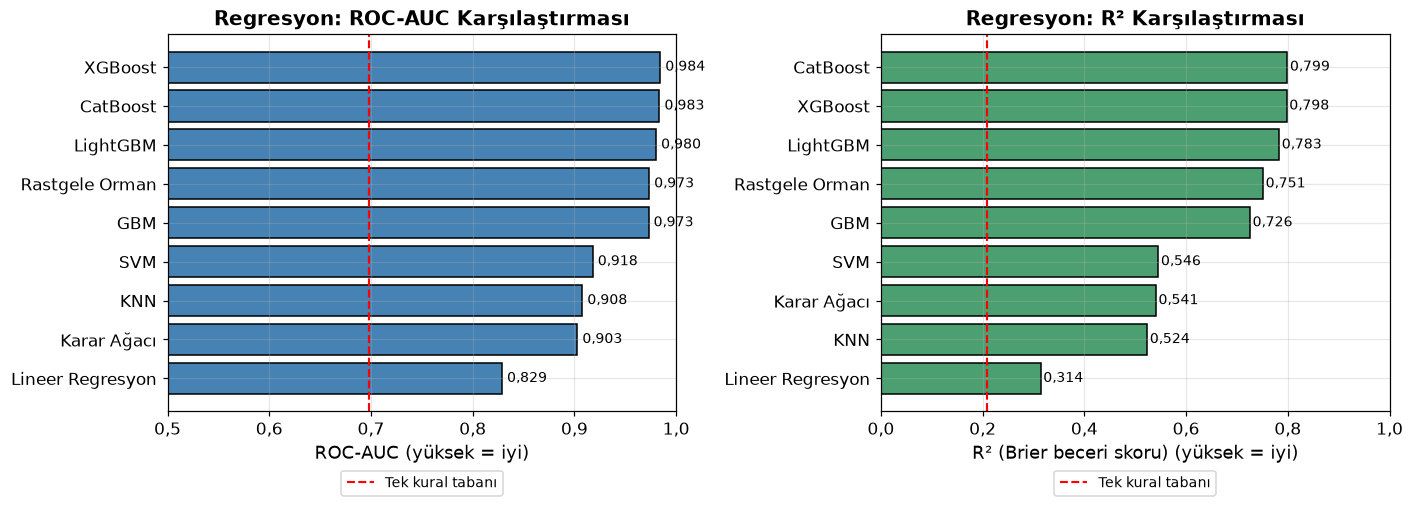

En yüksek AUC: XGBoost (0.9843); tek kural 0.6982
Tek kurala göre Brier iyileşmesi (%):
Algoritma
XGBoost             74.5
CatBoost            74.6
LightGBM            72.6
Rastgele Orman      68.6
GBM                 65.3
SVM                 42.6
KNN                 39.8
Karar Ağacı         42.0
Lineer Regresyon    13.3


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, olcut, ad, renk, alt in ((axes[0], "AUC", "ROC-AUC", "steelblue", 0.5),
                                 (axes[1], "R2", "R² (Brier beceri skoru)", "#4c9f70", 0.0)):
    t = tablo_reg.sort_values(olcut)
    ax.barh(t.index, t[olcut].clip(lower=alt), color=renk, edgecolor="k")
    ax.axvline(kur[olcut], color="red", ls="--", lw=1.4, label="Tek kural tabanı")
    ax.set_xlabel(f"{ad} (yüksek = iyi)")
    ax.set_title(f"Regresyon: {ad.split(' (')[0]} Karşılaştırması")
    ax.set_xlim(alt, 1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)
    for i, v in enumerate(t[olcut]):
        ax.text(max(v, alt) + 0.005, i, o.sayi(v, 3), va="center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_regresyon.png"), bbox_inches="tight")
plt.show()

en_iyi_reg = tablo_reg.index[0]
print(f"En yüksek AUC: {en_iyi_reg} ({tablo_reg['AUC'].iloc[0]:.4f}); tek kural {kur['AUC']:.4f}")
print("Tek kurala göre Brier iyileşmesi (%):")
print(tablo_reg["Brier_iyilesme_%"].round(1).to_string())

### 2.1 ROC Eğrileri

ROC eğrisi, skor eşiği 1'den 0'a indirildikçe yakalanan yangın noktalarının oranını
(duyarlılık, dikey eksen) yanlış alarm oranına (yatay eksen) karşı çizer. Eğri sol üst
köşeye ne kadar yakınsa skor o kadar iyidir; eğrinin altındaki alan AUC'dir. Köşegen
rastgele sıralamayı gösterir.

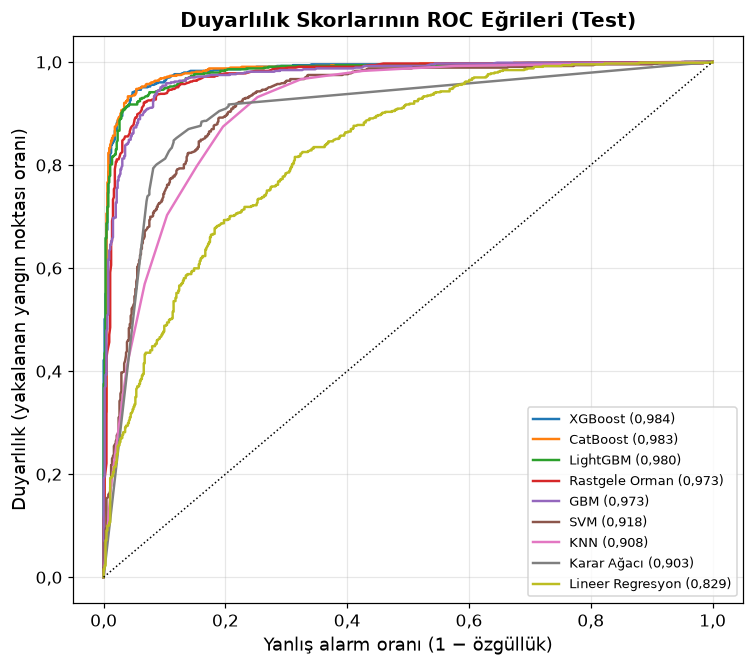

Yanlış alarm oranı %10 iken yakalanan yangın noktası oranı:
CatBoost            0.970
XGBoost             0.963
GBM                 0.954
LightGBM            0.949
Rastgele Orman      0.938
Karar Ağacı         0.812
SVM                 0.748
KNN                 0.688
Lineer Regresyon    0.488


In [4]:
fig, ax = plt.subplots(figsize=(7, 6.2))
gercek = test[o.HEDEF].values
roc_ozet = {}
for ad in tablo_reg.index:
    kod = {v: k for k, v in GORUNEN_AD.items()}[ad]
    skor = np.array(kayitlar[kod]["ek"].get("tahmin_reg") or kayitlar[kod]["ek"]["tahmin"], dtype=float)
    fpr, tpr, _ = roc_curve(gercek, skor)
    ax.plot(fpr, tpr, lw=1.6, label=f"{ad} ({o.sayi(tablo_reg.loc[ad, 'AUC'], 3)})")
    roc_ozet[ad] = float(np.interp(0.10, fpr, tpr))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("Yanlış alarm oranı (1 − özgüllük)")
ax.set_ylabel("Duyarlılık (yakalanan yangın noktası oranı)")
ax.set_title("Duyarlılık Skorlarının ROC Eğrileri (Test)")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_roc.png"), bbox_inches="tight")
plt.show()
OZET["roc_tpr_at_fpr10"] = roc_ozet
print("Yanlış alarm oranı %10 iken yakalanan yangın noktası oranı:")
print(pd.Series(roc_ozet).sort_values(ascending=False).round(3).to_string())

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [5]:
satirlar = []
for a, k in kayitlar.items():
    if k["siniflandirma"]:
        satirlar.append({"Algoritma": GORUNEN_AD[a], **k["siniflandirma"]})
tablo_cls = pd.DataFrame(satirlar).set_index("Algoritma").sort_values("F1_macro", ascending=False)
kurc = tb["kural_siniflandirma"]
tabanlar = pd.DataFrame([{"Algoritma": "Taban: tek kural", **kurc},
                         {"Algoritma": "Taban: çoğunluk sınıfı", **tb["siniflandirma"]}]).set_index("Algoritma")
OZET["siniflandirma"] = tablo_cls.round(6).reset_index().to_dict(orient="records")
pd.concat([tablo_cls, tabanlar]).round(4)

,Accuracy,BalancedAcc,F1_macro,F1_weighted
Algoritma,,,,
XGBoost,0.9470,0.9469,0.9469,0.9470
CatBoost,0.9415,0.9415,0.9415,0.9415
LightGBM,0.9415,0.9414,0.9415,0.9415
Rastgele Orman,0.9243,0.9245,0.9243,0.9243
GBM,0.9236,0.9234,0.9235,0.9235
Karar Ağacı,0.8736,0.8734,0.8735,0.8736
KNN,0.8385,0.8392,0.8385,0.8384
SVM,0.8362,0.8368,0.8362,0.8361
Naive Bayes,0.7395,0.7411,0.7381,0.7378


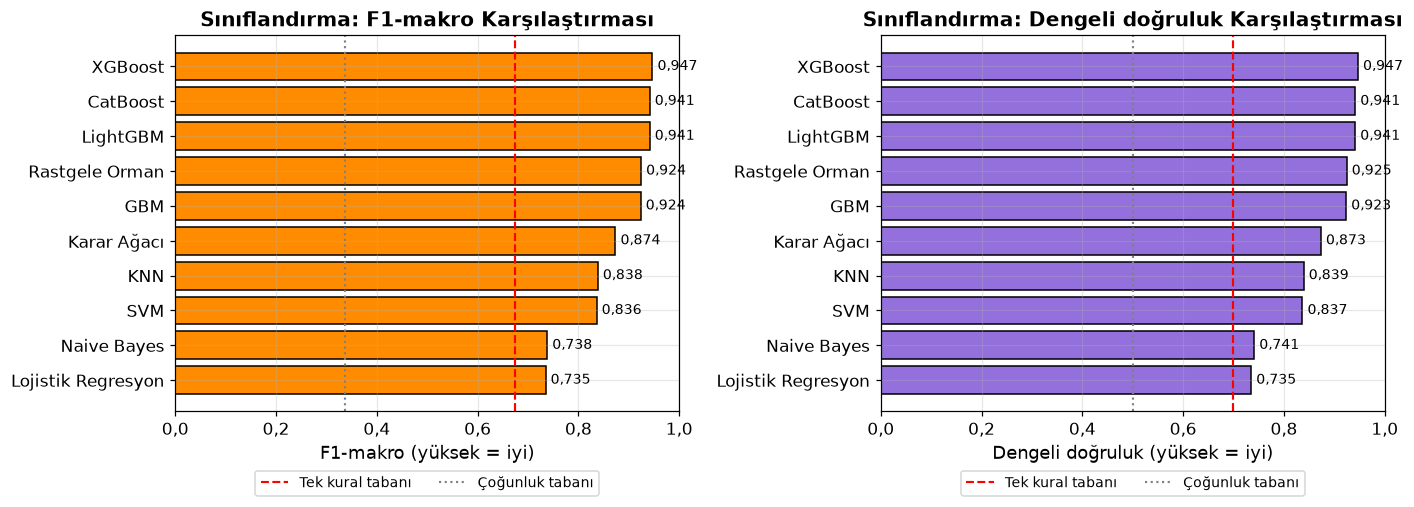

En yüksek F1-makro: XGBoost (0.9469); tek kural 0.6748


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, olcut, ad, renk in ((axes[0], "F1_macro", "F1-makro", "darkorange"),
                            (axes[1], "BalancedAcc", "Dengeli doğruluk", "mediumpurple")):
    t = tablo_cls.sort_values(olcut)
    ax.barh(t.index, t[olcut], color=renk, edgecolor="k")
    ax.axvline(kurc[olcut], color="red", ls="--", lw=1.4, label="Tek kural tabanı")
    ax.axvline(tb["siniflandirma"][olcut], color="gray", ls=":", lw=1.4, label="Çoğunluk tabanı")
    ax.set_xlim(0, 1)
    ax.set_xlabel(f"{ad} (yüksek = iyi)")
    ax.set_title(f"Sınıflandırma: {ad} Karşılaştırması")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
    for i, v in enumerate(t[olcut]):
        ax.text(v + 0.01, i, o.sayi(v, 3), va="center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_siniflandirma.png"), bbox_inches="tight")
plt.show()
en_iyi_cls = tablo_cls.index[0]
print(f"En yüksek F1-makro: {en_iyi_cls} ({tablo_cls['F1_macro'].iloc[0]:.4f}); tek kural {kurc['F1_macro']:.4f}")

## 4. Yangın Noktalarının Yakalanması

Uygulamada en çok önemsenen soru, yangın noktalarının ne kadarının "Yangın" olarak
işaretlendiği ve bu işaretlerin ne kadar güvenilir olduğudur. Aşağıda her model için
Yangın sınıfının **duyarlılığı** (gerçek yangın noktalarının kaçta kaçı yakalandı) ve
**kesinliği** (Yangın dendiğinde kaçta kaçı gerçekten yangın noktasıydı) verilir. Tek
kural tabanı da aynı ölçütlerle hesaplanmıştır.

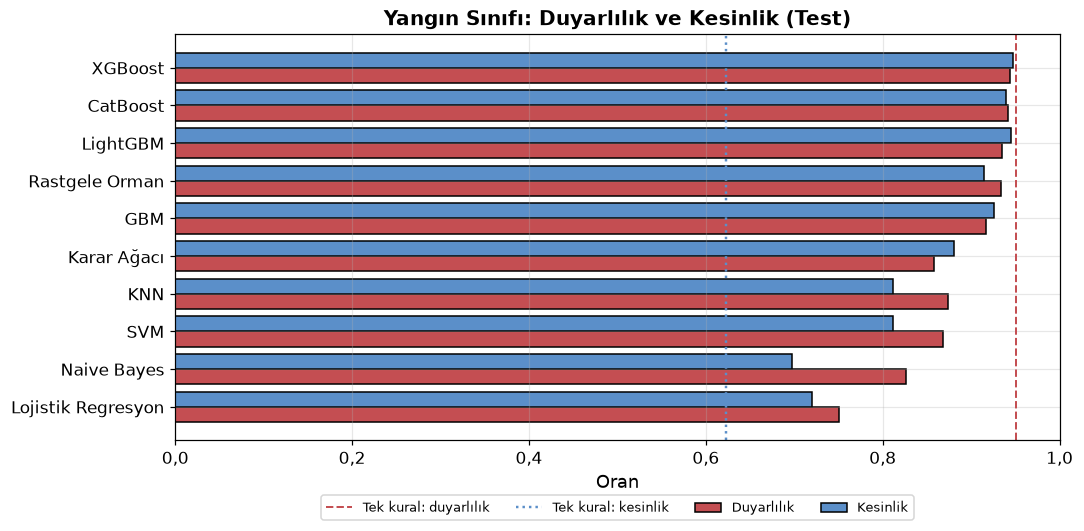

Test kümesindeki yangın noktası: 629
Tek kural: {'Duyarlılık': 0.9507, 'Kesinlik': 0.6229, 'F1': 0.7527}


,Duyarlılık,Kesinlik,F1
Algoritma,,,
XGBoost,0.9444,0.9474,0.9459
CatBoost,0.9412,0.9397,0.9404
LightGBM,0.9348,0.9453,0.9400
Rastgele Orman,0.9332,0.9143,0.9237
GBM,0.9173,0.9262,0.9217
Karar Ağacı,0.8585,0.8809,0.8696
KNN,0.8744,0.8112,0.8416
SVM,0.8680,0.8113,0.8387
Naive Bayes,0.8267,0.6980,0.7569


In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
gercek = test["Sinif"].astype(str).values == o.POZITIF
yakalama = []
for a, k in kayitlar.items():
    if not k["siniflandirma"]:
        continue
    tah = np.array(k["ek"].get("tahmin_sinif") or k["ek"]["tahmin"]) == o.POZITIF
    yakalama.append({"Algoritma": GORUNEN_AD[a], "Duyarlılık": recall_score(gercek, tah),
                     "Kesinlik": precision_score(gercek, tah), "F1": f1_score(gercek, tah)})
X_tr, X_te, _, _, yc_tr, _ = o.bolunme(df)
kutuk = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_tr, np.asarray(yc_tr, dtype=object))
kur_tah = kutuk.predict(X_te) == o.POZITIF
yakalama_kur = {"Duyarlılık": recall_score(gercek, kur_tah), "Kesinlik": precision_score(gercek, kur_tah),
                "F1": f1_score(gercek, kur_tah)}
tablo_yak = pd.DataFrame(yakalama).set_index("Algoritma").sort_values("F1", ascending=False)
OZET["yakalama"] = tablo_yak.round(6).reset_index().to_dict(orient="records")
OZET["yakalama_kural"] = yakalama_kur
OZET["yangin_test"] = int(gercek.sum())

fig, ax = plt.subplots(figsize=(10, 5))
t = tablo_yak.sort_values("F1")
y = np.arange(len(t)); w = 0.4
ax.barh(y - w / 2, t["Duyarlılık"], w, color="#c44e52", edgecolor="k", label="Duyarlılık")
ax.barh(y + w / 2, t["Kesinlik"], w, color="#5b8fc9", edgecolor="k", label="Kesinlik")
ax.axvline(yakalama_kur["Duyarlılık"], color="#c44e52", ls="--", lw=1.3, label="Tek kural: duyarlılık")
ax.axvline(yakalama_kur["Kesinlik"], color="#5b8fc9", ls=":", lw=1.6, label="Tek kural: kesinlik")
ax.set_yticks(y); ax.set_yticklabels(t.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Oran")
ax.set_title("Yangın Sınıfı: Duyarlılık ve Kesinlik (Test)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_yakalama.png"), bbox_inches="tight")
plt.show()
print(f"Test kümesindeki yangın noktası: {int(gercek.sum())}")
print("Tek kural:", {k: round(v, 4) for k, v in yakalama_kur.items()})
tablo_yak.round(4)

## 5. İki Görevin Birlikte Değerlendirilmesi

Her iki görevi de yerine getiren sekiz algoritmanın performansı 0–1 aralığında
normalleştirilmiştir (yüksek = iyi). Bu profil, algoritmaların birbirine göre konumunu
gösterir; normalleştirme yalnızca bu sekiz model arasında yapıldığından mutlak bir
başarı ölçüsü değildir.

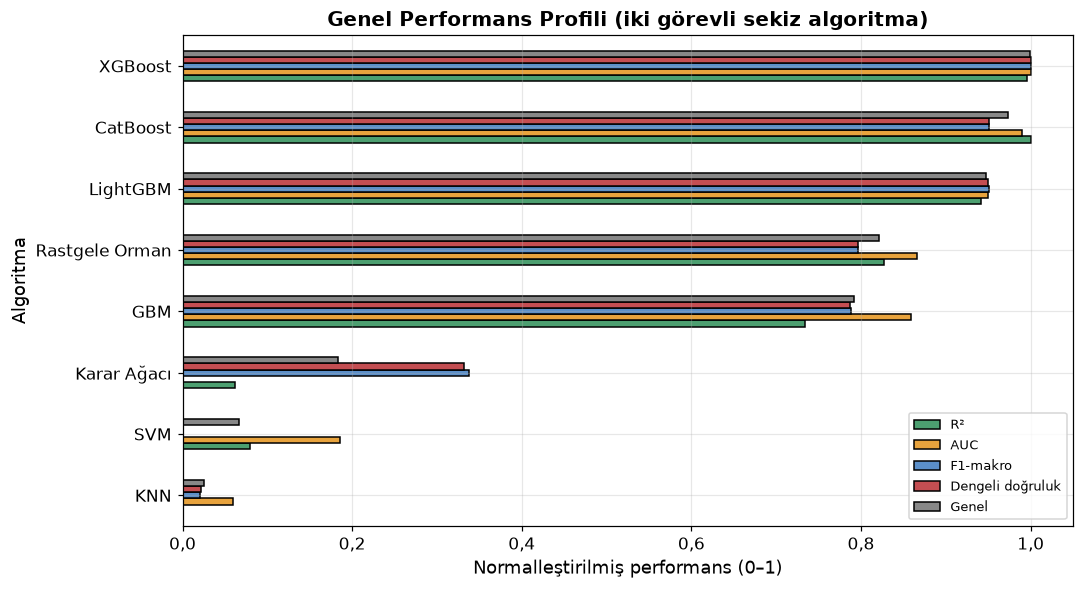

,R²,AUC,F1-makro,Dengeli doğruluk,Genel
Algoritma,,,,,
XGBoost,0.995,1.000,1.000,1.000,0.999
CatBoost,1.000,0.990,0.951,0.951,0.973
LightGBM,0.942,0.949,0.951,0.950,0.948
Rastgele Orman,0.827,0.866,0.796,0.797,0.821
GBM,0.733,0.859,0.789,0.787,0.792
Karar Ağacı,0.062,0.000,0.337,0.332,0.183
SVM,0.079,0.186,0.000,0.000,0.066
KNN,0.000,0.060,0.021,0.022,0.026


In [8]:
ortak_algo = [a for a, k in kayitlar.items() if k["regresyon"] and k["siniflandirma"]]
ozet = pd.DataFrame({
    "Algoritma": [GORUNEN_AD[a] for a in ortak_algo],
    "R2": [kayitlar[a]["regresyon"]["R2"] for a in ortak_algo],
    "AUC": [kayitlar[a]["regresyon"]["AUC"] for a in ortak_algo],
    "F1_macro": [kayitlar[a]["siniflandirma"]["F1_macro"] for a in ortak_algo],
    "BalancedAcc": [kayitlar[a]["siniflandirma"]["BalancedAcc"] for a in ortak_algo],
}).set_index("Algoritma")

def olcekle(s, ters=False):
    n = (s - s.min()) / (s.max() - s.min())
    return 1 - n if ters else n

norm = pd.DataFrame(index=ozet.index)
norm["R²"] = olcekle(ozet["R2"])
norm["AUC"] = olcekle(ozet["AUC"])
norm["F1-makro"] = olcekle(ozet["F1_macro"])
norm["Dengeli doğruluk"] = olcekle(ozet["BalancedAcc"])
norm["Genel"] = norm.mean(axis=1)
norm = norm.sort_values("Genel", ascending=False)
OZET["genel_profil"] = norm.round(6).reset_index().to_dict(orient="records")

ax = norm.sort_values("Genel").plot.barh(
    figsize=(10, 5.5), edgecolor="k",
    color=["#4c9f70", "#e8a33d", "#5b8fc9", "#c44e52", "#888888"])
ax.set_xlabel("Normalleştirilmiş performans (0–1)")
ax.set_title("Genel Performans Profili (iki görevli sekiz algoritma)")
ax.legend(loc="lower right", fontsize=8.5)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_genel.png"), bbox_inches="tight")
plt.show()
norm.round(3)

## 6. Güvenilirlik: Rastgele Test ve Sözde Mekânsal Doğrulama

Her algoritmanın sözde mekânsal grup doğrulamasında (eğitim kümesi, 5 kat; her katta
bazı iklim grupları bütünüyle dışarıda) elde ettiği değerlerin ortalaması ve standart
sapması, rastgele test kümesindeki değerle yan yana verilir. Aradaki fark **iyimserlik
payıdır**: rastgele bölünmenin, modelin hiç görmediği bir bölgedeki başarısını ne kadar
abarttığını gösterir. Büyük standart sapma, başarının bölgeden bölgeye değiştiğini gösterir.

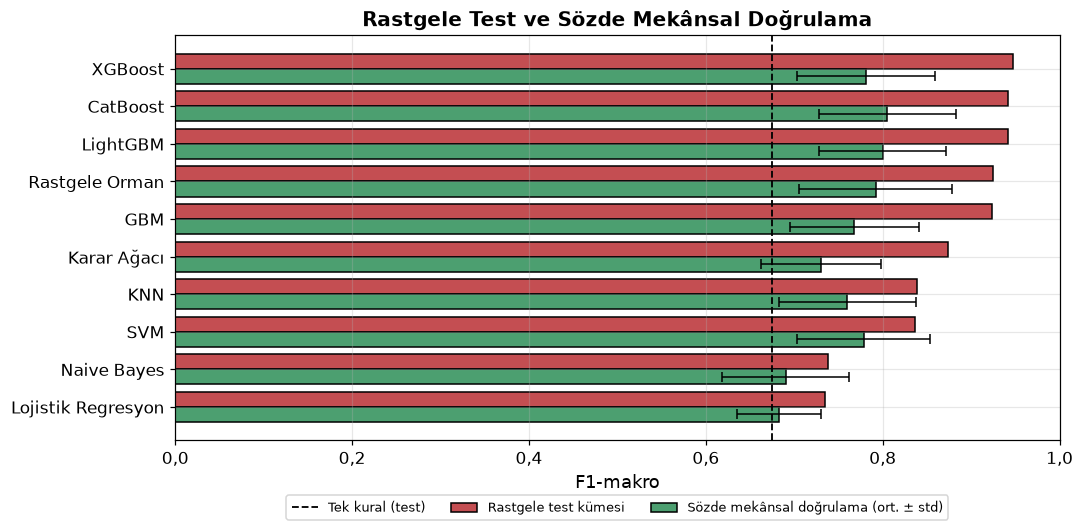

,R2_ort,R2_std,F1_ort,F1_std,Test_R2,Test_F1,F1_fark,R2_fark
Algoritma,,,,,,,,
CatBoost,0.4249,0.1442,0.8053,0.0773,0.7992,0.9415,0.1362,0.3742
GBM,0.2208,0.2347,0.7680,0.0732,0.7257,0.9235,0.1555,0.5049
Karar Ağacı,0.0402,0.2496,0.7305,0.0677,0.5407,0.8735,0.1430,0.5005
KNN,0.3449,0.1332,0.7602,0.0779,0.5237,0.8385,0.0783,0.1789
LightGBM,0.4108,0.1494,0.7999,0.0720,0.7831,0.9415,0.1416,0.3723
Lineer Regresyon,0.2126,0.0917,NaN,NaN,0.3142,NaN,NaN,0.1016
Lojistik Regresyon,NaN,NaN,0.6826,0.0476,NaN,0.7348,0.0522,NaN
Naive Bayes,NaN,NaN,0.6904,0.0717,NaN,0.7381,0.0477,NaN
Rastgele Orman,0.3901,0.1499,0.7920,0.0862,0.7514,0.9243,0.1324,0.3613


In [9]:
cvs = []
for a, k in kayitlar.items():
    cv = k["ek"]["cv"]
    cvs.append({"Algoritma": GORUNEN_AD[a], "R2_ort": cv["R2_ort"], "R2_std": cv["R2_std"],
                "F1_ort": cv["F1_ort"], "F1_std": cv["F1_std"],
                "Test_R2": k["regresyon"]["R2"] if k["regresyon"] else None,
                "Test_F1": k["siniflandirma"]["F1_macro"] if k["siniflandirma"] else None})
tablo_cv = pd.DataFrame(cvs).set_index("Algoritma")
tablo_cv["F1_fark"] = tablo_cv["Test_F1"] - tablo_cv["F1_ort"]
tablo_cv["R2_fark"] = tablo_cv["Test_R2"] - tablo_cv["R2_ort"]
OZET["cv"] = tablo_cv.reset_index().to_dict(orient="records")

t = tablo_cv.dropna(subset=["Test_F1"]).sort_values("Test_F1")
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(t)); w = 0.4
ax.barh(y + w / 2, t["Test_F1"], w, color="#c44e52", edgecolor="k", label="Rastgele test kümesi")
ax.barh(y - w / 2, t["F1_ort"], w, xerr=t["F1_std"], color="#4c9f70", edgecolor="k",
        error_kw={"elinewidth": 1, "capsize": 3}, label="Sözde mekânsal doğrulama (ort. ± std)")
ax.axvline(tb["kural_siniflandirma"]["F1_macro"], color="k", ls="--", lw=1.2, label="Tek kural (test)")
ax.set_yticks(y); ax.set_yticklabels(t.index)
ax.set_xlim(0, 1)
ax.set_xlabel("F1-makro")
ax.set_title("Rastgele Test ve Sözde Mekânsal Doğrulama")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_cv.png"), bbox_inches="tight")
plt.show()
tablo_cv.round(4)

## 7. Hata Analizi: En İyi Regresyon Modeli Nerede Yanılıyor?

En yüksek AUC değerine ulaşan modelin mutlak hatası (|gerçek − skor|), tek kural
tabanıyla arazi örtüsü sınıflarına ve iklim gruplarına göre karşılaştırılır. Böylece
modelin kazancının hangi arazi türlerinde ve hangi bölgelerde yoğunlaştığı görülür.

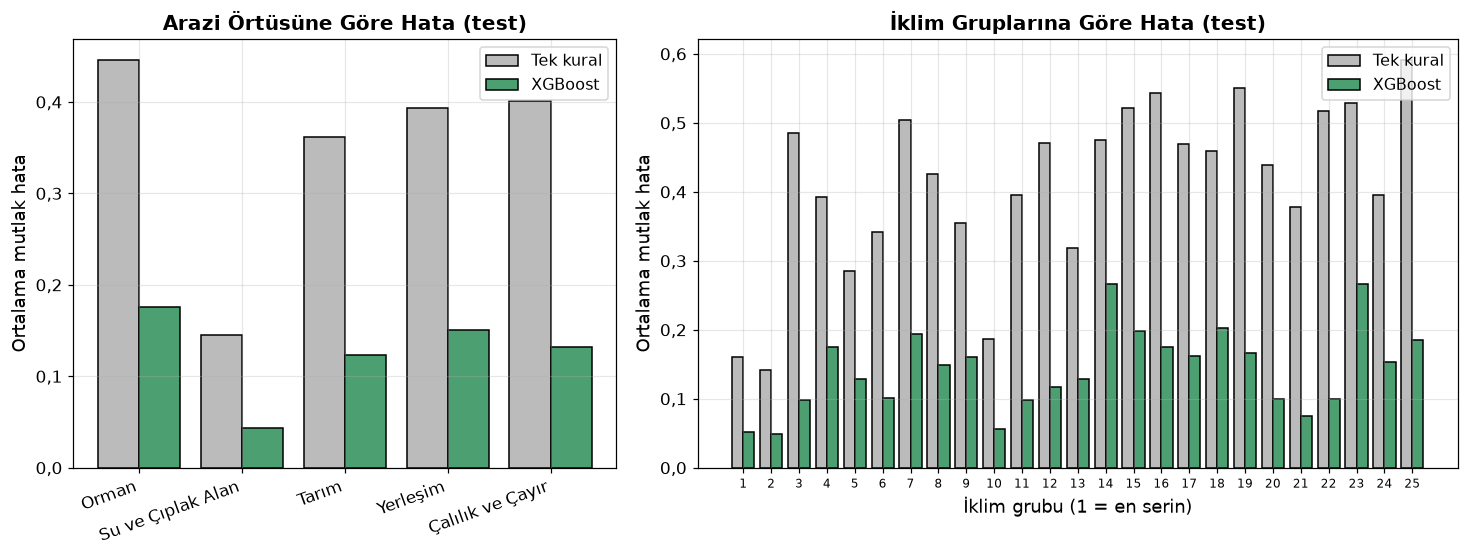

Arazi örtüsüne göre MAE:
                   hata_model  hata_kural  nokta
Arazi                                           
Orman                   0.175       0.446    382
Su ve Çıplak Alan       0.044       0.145     64
Tarım                   0.124       0.362    282
Yerleşim                0.150       0.393     28
Çalılık ve Çayır        0.132       0.401    526

Sınıflara göre MAE:
            hata_model  hata_kural
Sinif                             
Yangın Yok       0.120       0.382
Yangın           0.159       0.404

İklim grubu bazında iyileşme (%):
Iklim_Grubu
1     67.7
2     65.8
3     79.9
4     55.4
5     55.0
6     70.3
7     61.6
8     65.0
9     54.7
10    70.0
11    75.2
12    75.2
13    59.3
14    44.0
15    62.0
16    67.8
17    65.4
18    56.1
19    69.8
20    77.2
21    80.0
22    80.7
23    49.6
24    61.2
25    68.8


In [10]:
ad_kod = {v: k for k, v in GORUNEN_AD.items()}[en_iyi_reg]
test["tahmin"] = np.array(kayitlar[ad_kod]["ek"].get("tahmin_reg") or kayitlar[ad_kod]["ek"]["tahmin"])
from sklearn.tree import DecisionTreeRegressor
X_tr, X_te, yr_tr, _, _, _ = o.bolunme(df)
test["kural"] = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_tr, yr_tr).predict(X_te)
test["hata_model"] = (test[o.HEDEF] - test["tahmin"]).abs()
test["hata_kural"] = (test[o.HEDEF] - test["kural"]).abs()
arazi = test.groupby("Arazi")[["hata_model", "hata_kural"]].mean()
arazi["nokta"] = test.groupby("Arazi").size()
grup = test.groupby(o.GRUP)[["hata_model", "hata_kural"]].mean()
grup["iyilesme_%"] = (grup["hata_kural"] - grup["hata_model"]) / grup["hata_kural"] * 100
sinif_mae = test.groupby("Sinif", observed=False)[["hata_model", "hata_kural"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(arazi)); w = 0.4
axes[0].bar(x - w / 2, arazi["hata_kural"], w, color="#bbbbbb", edgecolor="k", label="Tek kural")
axes[0].bar(x + w / 2, arazi["hata_model"], w, color="#4c9f70", edgecolor="k", label=en_iyi_reg)
axes[0].set_xticks(x); axes[0].set_xticklabels(arazi.index, rotation=20, ha="right")
axes[0].set_ylabel("Ortalama mutlak hata")
axes[0].set_title("Arazi Örtüsüne Göre Hata (test)")
axes[0].legend()
x = np.arange(len(grup))
axes[1].bar(x - w / 2, grup["hata_kural"], w, color="#bbbbbb", edgecolor="k", label="Tek kural")
axes[1].bar(x + w / 2, grup["hata_model"], w, color="#4c9f70", edgecolor="k", label=en_iyi_reg)
axes[1].set_xticks(x); axes[1].set_xticklabels(grup.index.astype(str), fontsize=8)
axes[1].set_xlabel("İklim grubu (1 = en serin)")
axes[1].set_ylabel("Ortalama mutlak hata")
axes[1].set_title("İklim Gruplarına Göre Hata (test)")
axes[1].legend(loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_hata_analizi.png"), bbox_inches="tight")
plt.show()

OZET["hata_analizi"] = {
    "model": en_iyi_reg,
    "arazi": {i: {"model": float(r.hata_model), "kural": float(r.hata_kural), "nokta": int(r.nokta)}
              for i, r in arazi.iterrows()},
    "grup": {int(i): {"model": float(r.hata_model), "kural": float(r.hata_kural),
                      "iyilesme_%": float(r["iyilesme_%"])} for i, r in grup.iterrows()},
    "sinif": {str(s): {"model": float(r.hata_model), "kural": float(r.hata_kural)}
              for s, r in sinif_mae.iterrows()},
}
print("Arazi örtüsüne göre MAE:"); print(arazi.round(3).to_string())
print(); print("Sınıflara göre MAE:"); print(sinif_mae.round(3).to_string())
print(); print("İklim grubu bazında iyileşme (%):"); print(grup["iyilesme_%"].round(1).to_string())

In [11]:
OZET["en_iyi_regresyon"] = en_iyi_reg
OZET["en_iyi_siniflandirma"] = en_iyi_cls
OZET["taban"] = tb
with open(os.path.join(o.SONUC_DIR, "_karsilastirma.json"), "w", encoding="utf-8") as f:
    json.dump(OZET, f, ensure_ascii=False, indent=1, default=float)
print("Kaydedildi: sonuclar/_karsilastirma.json")

Kaydedildi: sonuclar/_karsilastirma.json


## 8. Öne Çıkan Bulgular

1. **Asıl rakip tek kuraldır.** Yüksekliğin 1.258 m'nin altında olup olmadığını soran
   tek bir eşik sorusu, hiçbir şey öğrenmeden AUC = 0,698 ve F1-makro = 0,675
   vermektedir; çoğunluk tabanının F1-makrosu ise yalnızca 0,337'dir. En iyi
   regresyon modeli (XGBoost) AUC'yi 0,984'e, en iyi sınıflandırıcı
   (XGBoost) F1-makroyu 0,947'ye çıkarmıştır.

2. **Algoritma ailesi belirleyicidir.** Ağaç tabanlı topluluk yöntemleri iki görevde de açık farkla
   öndedir; doğrusal yöntemler (Lineer ve Lojistik Regresyon, Naive Bayes) en alttadır. Yangın
   duyarlılığını belirleyen ilişkiler eşikli ve doğrusal değildir; etkenler arasındaki etkileşimler önemlidir.

3. **Tek kural yanlış alarm üretir.** Tek kural, alçaktaki bütün noktaları işaretlediği için yangın
   noktalarının %95,1'ini yakalar, ancak işaretlerin yalnızca %62,3'ü
   doğrudur. Topluluk yöntemleri duyarlılık ile kesinliği birlikte yükseltmektedir.

4. **Rastgele bölünme iyimserdir.** Sözde mekânsal grup doğrulamasında bütün modellerin başarısı
   düşmektedir; düşüş en esnek modellerde en büyüktür (XGBoost: F1-makroda 0,166),
   doğrusal modellerde en küçüktür (Naive Bayes: 0,048). Yeni bölgelerde en başarılı
   model CatBoost olmaktadır.

5. **İklim değişkenleri konum bilgisi taşır.** Yalnızca sıcaklık, yağış ve rüzgârla kurulan bir model rastgele
   doğrulamada AUC = 0,974 verirken yeni bölgelerde 0,766'ya düşmektedir. Bu
   değişkenlerin rastgele bölünmedeki başarısının bir kısmı, yangınla ilgili fiziksel bir bilgiden değil,
   konumun ezberlenmesinden gelmektedir.